<a href="https://colab.research.google.com/github/nageshnnazare/pytorch-expts/blob/main/6_Fashion_MNIST_GPU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Load dataset
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader

transform = T.Compose([T.ToTensor()])

train_ds = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_ds = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False, pin_memory=True)

print(f"Train size : {len(train_ds)}")
print(f"Test size  : {len(test_ds)}")
print(f"Classes    : {len(train_ds.classes)}")
print(train_ds.classes)

Train size : 60000
Test size  : 10000
Classes    : 10
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [ ]:
import torch

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


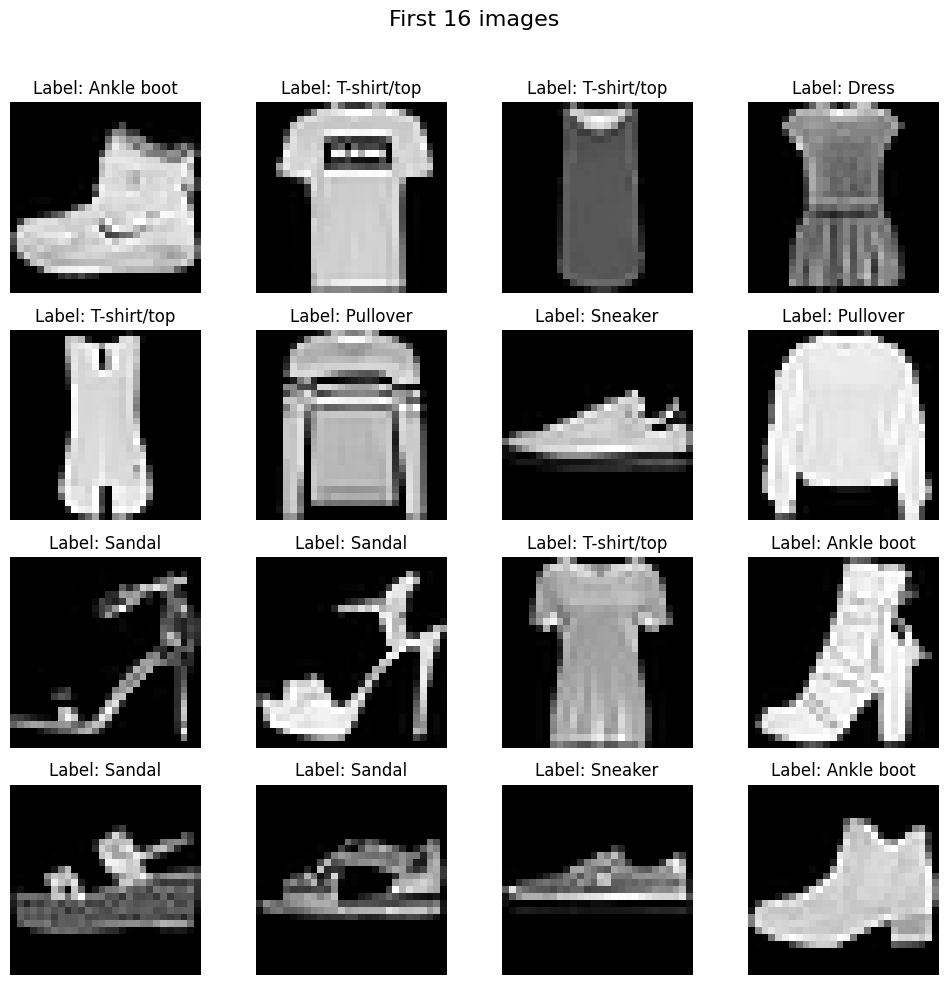

In [ ]:
import matplotlib.pyplot as plt

# Visualize
n, m = 4, 4
fig, axes = plt.subplots(nrows=n, ncols=m, figsize=(10,10))
fig.suptitle(f"First {n*m} images", fontsize=16)

for i, ax in enumerate(axes.flat):
  img, label = train_ds[i]
  ax.imshow(img.squeeze(), cmap='gray')
  ax.axis('off')
  ax.set_title(f"Label: {train_ds.classes[label]}")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
import torch.nn as nn

# Parameters
learning_rate = 0.1
epochs = 101
epsilon = 1e-6

# Define NN
class NeuralNetwork(nn.Module):
  def __init__(self, num_features, num_labels):
    super().__init__()
    self.input_size = num_features
    self.layer1_size = 128
    self.layer2_size = 64
    self.output_size = num_labels
    self.network = nn.Sequential(
        nn.Linear(self.input_size, self.layer1_size),
        nn.ReLU(),
        nn.Linear(self.layer1_size, self.layer2_size),
        nn.ReLU(),
        nn.Linear(self.layer2_size, self.output_size)
    )
    self.optim = torch.optim.SGD(self.network.parameters(), lr=learning_rate)
    self.loss_fn = nn.CrossEntropyLoss()

  def __print__(self):
    print(self.network)

  def forward(self, x):
    return self.network(x)

  def loss(self, y_pred, y):
    return self.loss_fn(y_pred, y)

  def backward(self, loss):
    self.optim.zero_grad()
    loss.backward()
    self.optim.step()

In [ ]:
# Create Model
model = NeuralNetwork(train_ds[0][0].numel(), len(train_ds.classes))
model = model.to(device)
print(model)
print(f"Batches : {len(train_loader)}")

# Training loop
for epoch in range(epochs):
    total_epoch_loss = 0
    for bfeatures, blabels in train_loader:
        # Move to GPU
        bfeatures = bfeatures.to(device).view(bfeatures.size(0), -1)
        blabels = blabels.to(device)

        # Forward pass
        y_pred = model(bfeatures)

        # Loss computation
        loss = model.loss(y_pred, blabels)

        # Backprop
        model.backward(loss)

        total_epoch_loss += loss.item()

    if epoch % 10 == 0:
        print(f"epoch : {epoch}, loss = {total_epoch_loss / len(train_loader)}")

NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
  (loss_fn): CrossEntropyLoss()
)
Batches : 938
epoch : 0, loss = 0.6933646697733702
epoch : 10, loss = 0.27120297595159587
epoch : 20, loss = 0.2145278879415506
epoch : 30, loss = 0.17648402539921848
epoch : 40, loss = 0.1468013332688065
epoch : 50, loss = 0.12531956752885315
epoch : 60, loss = 0.10944316813797712
epoch : 70, loss = 0.09100270310023637
epoch : 80, loss = 0.07776553048861465
epoch : 90, loss = 0.06954259316333687
epoch : 100, loss = 0.05730892174186181


In [ ]:
model.eval()

# Evaluate model
total = 0
correct = 0
print(f"Batches : {len(test_loader)}")
with torch.no_grad():
  for bfeatures, blabels in test_loader:
      # Move to GPU
      bfeatures = bfeatures.to(device).view(bfeatures.size(0), -1)
      blabels = blabels.to(device)

      y_pred = model(bfeatures)
      _, pred = torch.max(y_pred, 1)
      total += blabels.shape[0]
      correct += (pred == blabels).sum().item()

print(f"Test Accuracy : {correct * 100 / total}%")

# Evaluate model
total = 0
correct = 0
print(f"Batches : {len(train_loader)}")
with torch.no_grad():
  for bfeatures, blabels in train_loader:
      # Move to GPU
      bfeatures = bfeatures.to(device).view(bfeatures.size(0), -1)
      blabels = blabels.to(device)

      y_pred = model(bfeatures)
      _, pred = torch.max(y_pred, 1)
      total += blabels.shape[0]
      correct += (pred == blabels).sum().item()

print(f"Train Accuracy : {correct * 100 / total}%")

Batches : 157
Test Accuracy : 88.36%
Batches : 938
Train Accuracy : 97.41833333333334%


# Dropout & Batch Normalization & L2 Regularization
(for reducing overfitting)

In [ ]:
import torch.nn as nn

# Parameters
learning_rate = 0.1
epochs = 101
epsilon = 1e-6
lambdaf = 1e-4

# Define NN
class NeuralNetwork(nn.Module):
  def __init__(self, num_features, num_labels):
    super().__init__()
    self.input_size = num_features
    self.layer1_size = 128
    self.layer2_size = 64
    self.output_size = num_labels
    self.network = nn.Sequential(
        nn.Linear(self.input_size, self.layer1_size),
        nn.BatchNorm1d(self.layer1_size),
        nn.ReLU(),
        nn.Dropout(p=0.3),

        nn.Linear(self.layer1_size, self.layer2_size),
        nn.BatchNorm1d(self.layer2_size),
        nn.ReLU(),
        nn.Dropout(p=0.3),

        nn.Linear(self.layer2_size, self.output_size)
    )
    self.optim = torch.optim.SGD(self.network.parameters(),
                                 lr=learning_rate,
                                 weight_decay=lambdaf)
    self.loss_fn = nn.CrossEntropyLoss()

  def __print__(self):
    print(self.network)

  def forward(self, x):
    return self.network(x)

  def loss(self, y_pred, y):
    return self.loss_fn(y_pred, y)

  def backward(self, loss):
    self.optim.zero_grad()
    loss.backward()
    self.optim.step()

In [ ]:
# Create Model
model = NeuralNetwork(train_ds[0][0].numel(), len(train_ds.classes))
model = model.to(device)
print(model)
print(f"Batches : {len(train_loader)}")

# Training loop
for epoch in range(epochs):
    total_epoch_loss = 0
    for bfeatures, blabels in train_loader:
        # Move to GPU
        bfeatures = bfeatures.to(device).view(bfeatures.size(0), -1)
        blabels = blabels.to(device)

        # Forward pass
        y_pred = model(bfeatures)

        # Loss computation
        loss = model.loss(y_pred, blabels)

        # Backprop
        model.backward(loss)

        total_epoch_loss += loss.item()

    if epoch % 10 == 0:
        print(f"epoch : {epoch}, loss = {total_epoch_loss / len(train_loader)}")

NeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=10, bias=True)
  )
  (loss_fn): CrossEntropyLoss()
)
Batches : 938
epoch : 0, loss = 0.5911495460947948
epoch : 10, loss = 0.33309026028333444
epoch : 20, loss = 0.29220796364552176
epoch : 30, loss = 0.27184407126261734
epoch : 40, loss = 0.2581224621994409
epoch : 50, loss = 0.24655059980018051
epoch : 60, loss = 0.2386682000694308
epoch : 70, loss = 0.23108701183915392
epoch : 80, loss = 0.22543591161621912
epoch : 90, loss = 0.22092667074282285
epoch : 100, loss = 0.217285

In [ ]:
model.eval()

# Evaluate model
total = 0
correct = 0
print(f"Batches : {len(test_loader)}")
with torch.no_grad():
  for bfeatures, blabels in test_loader:
      # Move to GPU
      bfeatures = bfeatures.to(device).view(bfeatures.size(0), -1)
      blabels = blabels.to(device)

      y_pred = model(bfeatures)
      _, pred = torch.max(y_pred, 1)
      total += blabels.shape[0]
      correct += (pred == blabels).sum().item()

print(f"Test Accuracy : {correct * 100 / total}%")

# Evaluate model
total = 0
correct = 0
print(f"Batches : {len(train_loader)}")
with torch.no_grad():
  for bfeatures, blabels in train_loader:
      # Move to GPU
      bfeatures = bfeatures.to(device).view(bfeatures.size(0), -1)
      blabels = blabels.to(device)

      y_pred = model(bfeatures)
      _, pred = torch.max(y_pred, 1)
      total += blabels.shape[0]
      correct += (pred == blabels).sum().item()

print(f"Train Accuracy : {correct * 100 / total}%")

Batches : 157
Test Accuracy : 88.63%
Batches : 938
Train Accuracy : 94.87833333333333%


# Hyper parameter tuning

In [24]:
# Load dataset
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader

transform = T.Compose([T.ToTensor()])

train_ds = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_ds = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

import torch

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [29]:
import torch.nn as nn

class NeuralNetwork(nn.Module):
  def __init__(self, num_features, num_labels,
                      num_hidden_layers, neurons_per_layer,
                      dropout_rate, optimizer,
                      learning_rate, weight_decay):
    super().__init__()

    layers= []
    for i in range(num_hidden_layers):
      if i == 0:
        layers.append(nn.Linear(num_features, neurons_per_layer))
      else:
        layers.append(nn.Linear(neurons_per_layer, neurons_per_layer))
      layers.append(nn.BatchNorm1d(neurons_per_layer))
      layers.append(nn.ReLU())
      layers.append(nn.Dropout(p=dropout_rate))
    layers.append(nn.Linear(neurons_per_layer, num_labels))
    self.network = nn.Sequential(*layers)
    if optimizer == "SGD":
      self.optim = torch.optim.SGD(self.network.parameters(),
                                   lr=learning_rate, weight_decay=weight_decay)
    elif optimizer == "Adam":
      self.optim = torch.optim.Adam(self.network.parameters(),
                                    lr=learning_rate, weight_decay=weight_decay)
    elif optimizer == "RMSprop":
      self.optim = torch.optim.RMSprop(self.network.parameters(),
                                       lr=learning_rate, weight_decay=weight_decay)
    self.loss_fn = nn.CrossEntropyLoss()

  def __print__(self):
    print(self.network)

  def forward(self, x):
    return self.network(x)

  def loss(self, y_pred, y):
    return self.loss_fn(y_pred, y)

  def backward(self, loss):
    self.optim.zero_grad()
    loss.backward()
    self.optim.step()

In [31]:
def training_loop(model, train_loader, epochs, device):
  # Training loop
  for epoch in range(epochs):
      for bfeatures, blabels in train_loader:
          # Move to GPU
          bfeatures = bfeatures.to(device).view(bfeatures.size(0), -1)
          blabels = blabels.to(device)

          # Forward pass
          y_pred = model(bfeatures)

          # Loss computation
          loss = model.loss(y_pred, blabels)

          # Backprop
          model.backward(loss)

In [32]:
def run_evaluation(model, test_loader, device):
  model.eval()

  # Evaluate model
  total = 0
  correct = 0
  with torch.no_grad():
    for bfeatures, blabels in test_loader:
        # Move to GPU
        bfeatures = bfeatures.to(device).view(bfeatures.size(0), -1)
        blabels = blabels.to(device)

        y_pred = model(bfeatures)
        _, pred = torch.max(y_pred, 1)
        total += blabels.shape[0]
        correct += (pred == blabels).sum().item()

  return correct / total

In [34]:
# Objective function - hyperparameter tuning
def objective(trial):
  # hyper - Parameters
  num_hidden_layers = trial.suggest_int("hidden_layers",
                                        1, 5)
  neurons_per_layer = trial.suggest_int("neurons_per_layer",
                                        8, 128, step=8)
  epochs = trial.suggest_int("epochs",
                             10, 50, step=10)
  learning_rate = trial.suggest_float("learning_rate",
                                      1e-5, 1e-1, log=True)
  dropout_rate = trial.suggest_float("dropout_rate",
                                     0.0, 0.5, step=0.1)
  batch_size = trial.suggest_categorical("batch_size",
                                         [16, 32, 64, 128])
  optimizer = trial.suggest_categorical("optimizer",
                                        ["SGD", "Adam", "RMSprop"])
  weight_decay = trial.suggest_float("weight_decay",
                                     1e-5, 1e-3, log=True)

  train_loader = DataLoader(train_ds, batch_size,
                            shuffle=True, pin_memory=True)
  test_loader  = DataLoader(test_ds,  batch_size,
                            shuffle=False, pin_memory=True)

  input_dim = train_ds[0][0].numel()
  output_dim = len(train_ds.classes)

  # Create Model
  model = NeuralNetwork(input_dim, output_dim,
                        num_hidden_layers, neurons_per_layer,
                        dropout_rate, optimizer,
                        learning_rate, weight_decay)
  model = model.to(device)

  # Training loop
  training_loop(model, train_loader, epochs, device)

  # Evaluation
  accuracy = run_evaluation(model, test_loader, device)

  return accuracy

In [16]:
!pip install optuna --quiet
import optuna

In [ ]:
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

print(f"Best trial: {study.best_trial.value}")
print(f"Best params: {study.best_trial.params}")

[I 2026-11-08 12:51:09,115] A new study created in memory with name: no-name-1df95f33-e016-49b8-b1c9-bd14b38f9ad5
